# 04 · Análisis, pronóstico y alerta (R4 · R5 · Hito 3)
**Proyecto semestral · Sala de crisis COVID-19 · Gestión de Datos IN1232C · 2026-2**

Requiere `03_dw_estrella` (lee el Data Warehouse `covid_dw.db`).

1. Armar la **serie territorio × día** (países y regiones de Chile) desde el DW.
2. `alerta(territorio, fecha)`: alerta temprana con umbral.
3. `pronosticar(territorio, fecha_corte, horizonte=14)`: dos modelos, evaluados con MAE y MAPE en tres fechas de corte.
4. Respuestas a P1, P2, P4 y P6.
5. Guardar la serie para el tablero (Streamlit).

**Regla de oro del desafío en vivo:** `alerta()` y `pronosticar()` solo miran datos **hasta la fecha de corte**.

## Setup

In [1]:
import os
import shutil
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 2)

from google.colab import drive
drive.mount('/content/drive')

PROYECTO = '/content/drive/MyDrive/proyecto-gestion-datos-2026'
LIMPIOS = os.path.join(PROYECTO, 'data', 'clean')

# Copiamos el DW al disco de la sesión: las consultas son más rápidas
shutil.copy(os.path.join(PROYECTO, 'data', 'dw', 'covid_dw.db'), '/content/covid_dw.db')
dw = sqlite3.connect('/content/covid_dw.db')

## 1 · Serie territorio × día

Desde el DW sumamos los **acumulados** por país (y por región, para Chile) en cada día. Los nuevos se calculan como la diferencia del acumulado con el día anterior.

- Se **excluye el archivo defectuoso del 23-may-2022** (decisión de `02_calidad`): si no, aparece una caída y un rebote falsos en 136 países.
- Si el acumulado baja (corrección), el nuevo queda negativo; para las medias móviles se usa 0 ese día (no se inventa el reparto).
- Las entidades especiales (cruceros, JJ.OO., Antártica) no entran.

In [2]:
paises = pd.read_sql("""
    SELECT t.pais AS territorio, t.pais, 'pais' AS nivel, d.fecha,
           SUM(f.casos_acum) AS casos_acum, SUM(f.fallecidos_acum) AS fallecidos_acum
    FROM fact_covid f
    JOIN dim_fecha d      ON d.fecha_key = f.fecha_key
    JOIN dim_territorio t ON t.territorio_key = f.territorio_key
    WHERE f.archivo_defectuoso = 0
    GROUP BY t.pais, d.fecha
""", dw)

regiones = pd.read_sql("""
    SELECT 'Chile · ' || t.region AS territorio, t.pais, 'region' AS nivel, d.fecha,
           SUM(f.casos_acum) AS casos_acum, SUM(f.fallecidos_acum) AS fallecidos_acum
    FROM fact_covid f
    JOIN dim_fecha d      ON d.fecha_key = f.fecha_key
    JOIN dim_territorio t ON t.territorio_key = f.territorio_key
    WHERE f.archivo_defectuoso = 0 AND t.pais = 'Chile' AND t.nivel = 'region' AND t.region <> 'Unknown'
    GROUP BY t.region, d.fecha
""", dw)

# Población y coordenadas: fila del país (o de la región) en la dimensión territorio
dim = pd.read_sql('SELECT * FROM dim_territorio WHERE en_tabla_uid = 1', dw)
pob_pais = dim[dim['nivel'] == 'pais'][['pais', 'poblacion', 'lat', 'long', 'iso3']]
pob_pais = pob_pais.rename(columns={'pais': 'territorio'})
pob_region = dim[(dim['pais'] == 'Chile') & (dim['nivel'] == 'region')][['region', 'poblacion', 'lat', 'long', 'iso3']]
pob_region['territorio'] = 'Chile · ' + pob_region['region']
pob_region = pob_region.drop(columns='region')

serie = pd.concat([paises.merge(pob_pais, on='territorio'),
                   regiones.merge(pob_region, on='territorio')], ignore_index=True)

entidades_especiales = ['Diamond Princess', 'MS Zaandam', 'Summer Olympics 2020', 'Winter Olympics 2022', 'Antarctica']
serie = serie[~serie['territorio'].isin(entidades_especiales) & (serie['poblacion'] > 0)]

serie['fecha'] = pd.to_datetime(serie['fecha'])
serie = serie.sort_values(['territorio', 'fecha']).reset_index(drop=True)
serie['casos_nuevos'] = serie.groupby('territorio')['casos_acum'].diff()
serie['fallecidos_nuevos'] = serie.groupby('territorio')['fallecidos_acum'].diff()

# Media móvil de 7 días (días negativos = 0) e incidencia de 7 días por 100.000 habitantes
serie['casos_mm7'] = serie.groupby('territorio')['casos_nuevos'].transform(lambda s: s.clip(lower=0).rolling(7).mean())
serie['fallecidos_mm7'] = serie.groupby('territorio')['fallecidos_nuevos'].transform(lambda s: s.clip(lower=0).rolling(7).mean())
serie['incidencia_7d'] = serie['casos_mm7'] * 7 / serie['poblacion'] * 100000

print(f"{len(serie):,} filas · {serie[serie['nivel'] == 'pais']['territorio'].nunique()} países · "
      f"{serie[serie['nivel'] == 'region']['territorio'].nunique()} regiones de Chile")
serie[serie['territorio'] == 'Chile'].tail()

231,134 filas · 196 países · 16 regiones de Chile


,territorio,pais,nivel,fecha,casos_acum,fallecidos_acum,poblacion,lat,long,iso3,casos_nuevos,fallecidos_nuevos,casos_mm7,fallecidos_mm7,incidencia_7d
39562,Chile,Chile,pais,2023-03-05,5.18e+06,64230.0,1.91e+07,-35.68,-71.54,CHL,2559.0,8.0,2430.43,9.14,89.00
39563,Chile,Chile,pais,2023-03-06,5.18e+06,64247.0,1.91e+07,-35.68,-71.54,CHL,2031.0,17.0,2491.14,10.43,91.22
39564,Chile,Chile,pais,2023-03-07,5.18e+06,64250.0,1.91e+07,-35.68,-71.54,CHL,2222.0,3.0,2607.71,10.71,95.49
39565,Chile,Chile,pais,2023-03-08,5.19e+06,64254.0,1.91e+07,-35.68,-71.54,CHL,3798.0,4.0,2748.71,11.00,100.65
39566,Chile,Chile,pais,2023-03-09,5.19e+06,64273.0,1.91e+07,-35.68,-71.54,CHL,3906.0,19.0,2885.14,10.86,105.65


## 2 · Alerta temprana

**Indicador:** incidencia de los últimos 7 días por 100.000 habitantes, comparada con la de los 7 días anteriores.

**Umbral:** la alerta se activa si la incidencia **sube más de 50 %** en una semana **y** ya supera **20 casos por 100.000** (para no alertar por subidas de 2 a 4 casos).

La función recibe la fecha como parámetro y **solo usa datos hasta esa fecha**.

In [3]:
UMBRAL_VARIACION = 50   # % de alza semanal
UMBRAL_MINIMO = 20      # casos por 100.000 en 7 días

def alerta(territorio, fecha):
    fecha = pd.Timestamp(fecha)
    s = serie[(serie['territorio'] == territorio) & (serie['fecha'] <= fecha)]   # solo el pasado
    nuevos = s['casos_nuevos'].clip(lower=0)
    pob = s['poblacion'].iloc[0]
    inc_actual = nuevos.tail(7).sum() / pob * 100000
    inc_anterior = nuevos.iloc[-14:-7].sum() / pob * 100000
    if inc_anterior > 0:
        variacion = (inc_actual / inc_anterior - 1) * 100
    else:
        variacion = np.nan
    activa = (variacion > UMBRAL_VARIACION) and (inc_actual >= UMBRAL_MINIMO)
    return {'territorio': territorio, 'fecha': fecha.date(), 'incidencia_7d': round(inc_actual, 1),
            'incidencia_semana_anterior': round(inc_anterior, 1), 'variacion_%': round(variacion, 1),
            'alerta': 'ACTIVA' if activa else 'no'}

alerta('Chile', '2021-12-28')

{'territorio': 'Chile',
 'fecha': datetime.date(2021, 12, 28),
 'incidencia_7d': np.float64(41.9),
 'incidencia_semana_anterior': np.float64(45.3),
 'variacion_%': np.float64(-7.5),
 'alerta': 'no'}

### ¿Cuántas olas tuvo Chile y con cuánta anticipación las habría detectado la alerta?

**Ola:** período en que la incidencia de 7 días supera **100 por 100.000** durante al menos 14 días (si la incidencia baja menos de 14 días y vuelve a subir, es la misma ola).

In [4]:
def olas(territorio, nivel=100, min_dias=14):
    s = serie[serie['territorio'] == territorio].set_index('fecha')['incidencia_7d']
    sobre = s > nivel
    # cada vez que cambia de "bajo" a "sobre" empieza un tramo
    tramo = (sobre != sobre.shift()).cumsum()
    tramos = s[sobre].groupby(tramo[sobre]).agg(inicio=lambda x: x.index.min(), fin=lambda x: x.index.max())
    # unir tramos separados por menos de min_dias
    lista = []
    for _, t in tramos.iterrows():
        if lista and (t['inicio'] - lista[-1]['fin']).days < min_dias:
            lista[-1]['fin'] = t['fin']
        else:
            lista.append({'inicio': t['inicio'], 'fin': t['fin']})
    res = pd.DataFrame(lista)
    res = res[(res['fin'] - res['inicio']).dt.days + 1 >= min_dias].reset_index(drop=True)
    res['dias'] = (res['fin'] - res['inicio']).dt.days + 1
    res['peak_incidencia_7d'] = [s[i:f].max().round(0) for i, f in zip(res['inicio'], res['fin'])]
    res['fecha_peak'] = [s[i:f].idxmax().date() for i, f in zip(res['inicio'], res['fin'])]
    res.index = [f'Ola {k + 1}' for k in range(len(res))]
    return res

olas_chile = olas('Chile')
olas_chile

,inicio,fin,dias,peak_incidencia_7d,fecha_peak
Ola 1,2020-05-20,2020-07-12,54,378.0,2020-06-17
Ola 2,2021-01-07,2021-07-09,184,268.0,2021-04-14
Ola 3,2022-01-09,2022-04-16,98,1306.0,2022-02-13
Ola 4,2022-05-10,2023-01-17,253,386.0,2022-06-17


In [5]:
# Evaluar la alerta en toda la historia de Chile (cada día, con datos solo hasta ese día)
fechas = pd.date_range('2020-03-20', '2023-03-09')
historia = pd.DataFrame([alerta('Chile', f) for f in fechas])
historia['fecha'] = pd.to_datetime(historia['fecha'])
historia['activa'] = historia['alerta'] == 'ACTIVA'

# Episodios de alerta: días seguidos con la alerta activa
historia['episodio'] = (historia['activa'] != historia['activa'].shift()).cumsum()
episodios = historia[historia['activa']].groupby('episodio')['fecha'].agg(['min', 'max'])

# Anticipación: primer día con alerta en los 30 días antes del inicio de cada ola
anticipacion = []
for nombre, ola in olas_chile.iterrows():
    ventana = historia[(historia['fecha'] >= ola['inicio'] - pd.Timedelta(days=30)) &
                       (historia['fecha'] <= ola['inicio']) & historia['activa']]
    if len(ventana) > 0:
        dias = (ola['inicio'] - ventana['fecha'].min()).days
    else:
        dias = np.nan
    anticipacion.append({'ola': nombre, 'inicio_ola': ola['inicio'].date(), 'dias_de_anticipacion': dias})
anticipacion = pd.DataFrame(anticipacion)

# Falsa alarma: episodio de alerta que no termina en una ola en los 30 días siguientes
def es_falsa(inicio_alerta):
    for _, ola in olas_chile.iterrows():
        if inicio_alerta <= ola['fin'] and ola['inicio'] - inicio_alerta <= pd.Timedelta(days=30):
            return False
    return True

episodios['falsa_alarma'] = episodios['min'].apply(es_falsa)
print('Episodios de alerta:', len(episodios), '| falsas alarmas:', episodios['falsa_alarma'].sum())
anticipacion

Episodios de alerta: 10 | falsas alarmas: 1


,ola,inicio_ola,dias_de_anticipacion
0,Ola 1,2020-05-20,19.0
1,Ola 2,2021-01-07,NaN
2,Ola 3,2022-01-09,2.0
3,Ola 4,2022-05-10,NaN


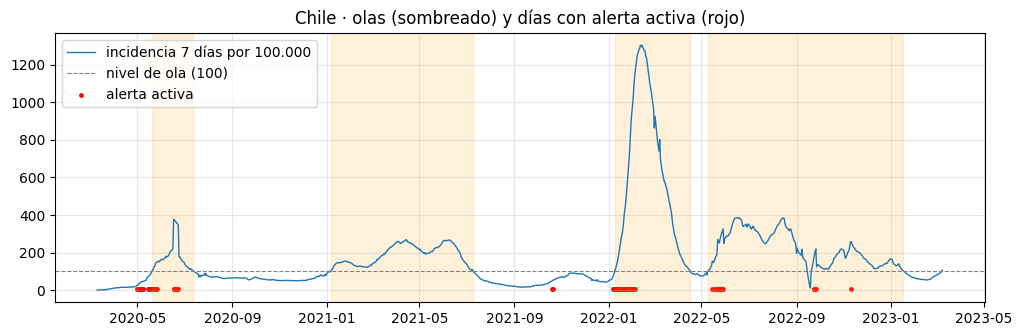

In [6]:
chile = serie[serie['territorio'] == 'Chile']
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(chile['fecha'], chile['incidencia_7d'], linewidth=1, label='incidencia 7 días por 100.000')
ax.axhline(100, color='gray', linestyle='--', linewidth=0.8, label='nivel de ola (100)')
alertas = historia[historia['activa']]
ax.scatter(alertas['fecha'], [5] * len(alertas), color='red', s=6, label='alerta activa')
for nombre, ola in olas_chile.iterrows():
    ax.axvspan(ola['inicio'], ola['fin'], color='orange', alpha=0.15)
ax.set_title('Chile · olas (sombreado) y días con alerta activa (rojo)')
ax.legend(loc='upper left')
ax.grid(alpha=0.3)
plt.show()

## 3 · Pronóstico

`pronosticar(territorio, fecha_corte, horizonte=14)` pronostica los **casos nuevos diarios (media móvil de 7 días)** de los próximos `horizonte` días, usando **solo datos hasta `fecha_corte`**:

| Modelo | Idea |
|---|---|
| **Base: media móvil** | Los próximos 14 días serán iguales al promedio de la última semana |
| **Tendencia** | Recta ajustada (`np.polyfit`) al logaritmo de la media móvil de las últimas 2 semanas: si los casos venían creciendo un x % diario, siguen creciendo igual |

Para evaluar, `comparar()` pone al lado lo que **realmente pasó** y calcula MAE y MAPE.

In [7]:
def pronosticar(territorio, fecha_corte, horizonte=14):
    fecha_corte = pd.Timestamp(fecha_corte)
    s = serie[(serie['territorio'] == territorio) & (serie['fecha'] <= fecha_corte)]   # solo el pasado
    mm7 = s['casos_mm7'].dropna()

    # Modelo base: repetir la última media móvil
    base = [mm7.iloc[-1]] * horizonte

    # Modelo de tendencia: recta sobre el log de las últimas 14 medias móviles
    y = np.log(mm7.tail(14).clip(lower=1))
    x = np.arange(len(y))
    pendiente, intercepto = np.polyfit(x, y, 1)
    futuro = np.arange(len(y), len(y) + horizonte)
    tendencia = np.exp(intercepto + pendiente * futuro)

    fechas = pd.date_range(fecha_corte + pd.Timedelta(days=1), periods=horizonte)
    return pd.DataFrame({'fecha': fechas, 'media_movil': np.round(base), 'tendencia': np.round(tendencia)})


def comparar(territorio, fecha_corte, horizonte=14):
    p = pronosticar(territorio, fecha_corte, horizonte)
    real = serie[serie['territorio'] == territorio][['fecha', 'casos_mm7']].rename(columns={'casos_mm7': 'real'})
    p = p.merge(real, on='fecha', how='left')
    errores = {}
    for modelo in ['media_movil', 'tendencia']:
        error = (p[modelo] - p['real']).abs()
        errores[modelo] = {'MAE': round(error.mean()), 'MAPE %': round((error / p['real'].clip(lower=1)).mean() * 100, 1)}
    return p, pd.DataFrame(errores).T

pronosticar('Chile', '2021-12-20')

,fecha,media_movil,tendencia
0,2021-12-21,1248.0,1227.0
1,2021-12-22,1248.0,1199.0
2,2021-12-23,1248.0,1172.0
3,2021-12-24,1248.0,1145.0
4,2021-12-25,1248.0,1119.0
5,2021-12-26,1248.0,1093.0
6,2021-12-27,1248.0,1068.0
7,2021-12-28,1248.0,1044.0
8,2021-12-29,1248.0,1020.0
9,2021-12-30,1248.0,996.0


In [8]:
# Backtesting: tres fechas de corte en Chile (subida, peak de ómicron y bajada)
cortes = ['2021-03-15', '2021-12-27', '2022-02-15']
filas = []
for corte in cortes:
    _, err = comparar('Chile', corte)
    for modelo, fila in err.iterrows():
        filas.append({'fecha_corte': corte, 'modelo': modelo, 'MAE': fila['MAE'], 'MAPE %': fila['MAPE %']})
backtest = pd.DataFrame(filas)
backtest.pivot_table(index='fecha_corte', columns='modelo', values='MAPE %')

modelo,media_movil,tendencia
fecha_corte,,
2021-03-15,13.6,3.7
2021-12-27,26.4,32.6
2022-02-15,16.6,37.2


In [9]:
backtest.groupby('modelo')[['MAE', 'MAPE %']].mean().round(1)

,MAE,MAPE %
modelo,,
media_movil,2012.0,18.9
tendencia,3826.3,24.5


**Interpretación:** ningún modelo gana siempre. Cuando la curva **cambia de dirección** (peak o inicio de ola), el de tendencia se equivoca más porque sigue la dirección anterior; cuando la curva **sigue subiendo**, la media móvil se queda corta. Por eso en el tablero se muestran los dos.

## 4 · Respuestas
### P1 · ¿Cómo vivió Chile la pandemia comparado con el resto de Sudamérica?

In [10]:
sudamerica = ['Argentina', 'Bolivia', 'Brazil', 'Chile', 'Colombia', 'Ecuador', 'Guyana',
              'Paraguay', 'Peru', 'Suriname', 'Uruguay', 'Venezuela']
ultimo = serie[(serie['fecha'] == serie['fecha'].max()) & serie['territorio'].isin(sudamerica)].copy()
ultimo['casos_x100k'] = (ultimo['casos_acum'] / ultimo['poblacion'] * 100000).round(0)
ultimo['fallecidos_x100k'] = (ultimo['fallecidos_acum'] / ultimo['poblacion'] * 100000).round(1)
p1 = ultimo.sort_values('fallecidos_x100k', ascending=False)[['territorio', 'casos_x100k', 'fallecidos_x100k']]
p1['posicion_fallecidos'] = range(1, len(p1) + 1)
p1

,territorio,casos_x100k,fallecidos_x100k,posicion_fallecidos
168750,Peru,13610.0,665.8,1
39566,Chile,27162.0,336.2,2
26399,Brazil,17443.0,329.0,3
7689,Argentina,22225.0,288.7,4
58175,Colombia,12498.0,279.7,5
167652,Paraguay,11334.0,278.7,6
200421,Suriname,14058.0,239.3,7
222641,Uruguay,29775.0,219.3,8
73470,Ecuador,5992.0,204.1,9
23118,Bolivia,10231.0,191.6,10


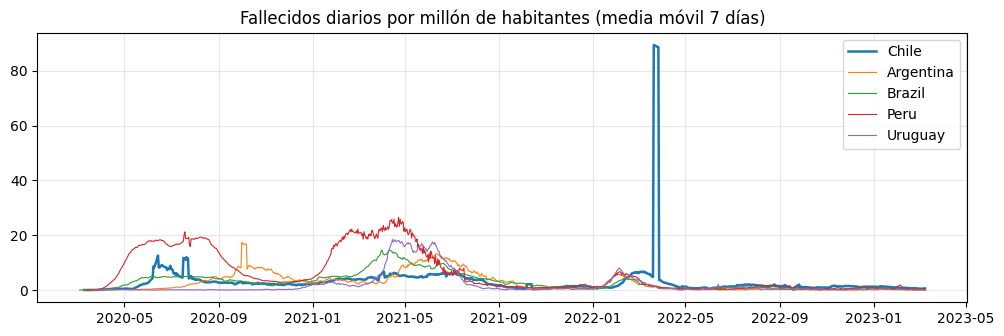

Olas de Chile: 4
Peor ola (mayor incidencia): Ola 3 - 2022-02-13


In [11]:
fig, ax = plt.subplots(figsize=(12, 3.5))
for pais in ['Chile', 'Argentina', 'Brazil', 'Peru', 'Uruguay']:
    s = serie[serie['territorio'] == pais]
    fall = s['fallecidos_mm7'] / s['poblacion'] * 1000000
    ax.plot(s['fecha'], fall, linewidth=1.8 if pais == 'Chile' else 0.8, label=pais)
ax.set_title('Fallecidos diarios por millón de habitantes (media móvil 7 días)')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

print('Olas de Chile:', len(olas_chile))
print('Peor ola (mayor incidencia):', olas_chile['peak_incidencia_7d'].idxmax(),
      '-', olas_chile.loc[olas_chile['peak_incidencia_7d'].idxmax(), 'fecha_peak'])

### P2 · ¿Qué regiones de Chile fueron más golpeadas y en qué ola?
Desde el 1-jun-2020 (Chile informa por región desde el 20-may-2020).

In [12]:
reg = serie[(serie['nivel'] == 'region') & (serie['fecha'] >= '2020-06-01')].copy()
p2 = reg.groupby('territorio').agg(casos=('casos_nuevos', 'sum'), fallecidos=('fallecidos_nuevos', 'sum'),
                                   poblacion=('poblacion', 'first'), lat=('lat', 'first'), long=('long', 'first'))
p2['casos_x100k'] = (p2['casos'] / p2['poblacion'] * 100000).round(0)
p2['fallecidos_x100k'] = (p2['fallecidos'] / p2['poblacion'] * 100000).round(1)
p2 = p2.sort_values('fallecidos_x100k', ascending=False)
p2['posicion'] = range(1, len(p2) + 1)
print('Biobío:', p2.loc['Chile · Biobio', 'posicion'], 'de', len(p2), 'en fallecidos por 100.000')
p2[['casos_x100k', 'fallecidos_x100k', 'posicion']]

Biobío: 10 de 16 en fallecidos por 100.000


,casos_x100k,fallecidos_x100k,posicion
territorio,,,
Chile · Magallanes,39990.0,453.4,1
Chile · Metropolitana,26528.0,423.1,2
Chile · Arica y Parinacota,34989.0,395.0,3
Chile · Los Rios,38431.0,365.1,4
Chile · Valparaiso,26970.0,352.2,5
Chile · Tarapaca,33634.0,348.5,6
Chile · Maule,33064.0,319.5,7
Chile · Antofagasta,29842.0,317.7,8
Chile · Los Lagos,29226.0,309.4,9


In [13]:
# ¿En qué ola? Casos por 100.000 de cada región en cada ola de Chile
filas = []
for nombre, ola in olas_chile.iterrows():
    tramo = reg[(reg['fecha'] >= ola['inicio']) & (reg['fecha'] <= ola['fin'])]
    t = tramo.groupby('territorio').agg(casos=('casos_nuevos', 'sum'), poblacion=('poblacion', 'first'))
    t['ola'] = nombre
    t['casos_x100k'] = (t['casos'] / t['poblacion'] * 100000).round(0)
    filas.append(t.reset_index())
por_ola = pd.concat(filas).pivot_table(index='territorio', columns='ola', values='casos_x100k')
por_ola['ola_mas_dura'] = por_ola.idxmax(axis=1)
por_ola

ola,Ola 1,Ola 2,Ola 3,Ola 4,ola_mas_dura
territorio,,,,,
Chile · Antofagasta,1529.0,5555.0,8954.0,9452.0,Ola 4
Chile · Araucania,159.0,7336.0,11455.0,7506.0,Ola 3
Chile · Arica y Parinacota,817.0,6438.0,11248.0,10361.0,Ola 3
Chile · Atacama,470.0,5834.0,11924.0,16528.0,Ola 4
Chile · Aysen,38.0,6020.0,13983.0,9881.0,Ola 3
Chile · Biobio,416.0,6161.0,11692.0,9362.0,Ola 3
Chile · Coquimbo,459.0,4165.0,9268.0,10475.0,Ola 4
Chile · Los Lagos,172.0,7030.0,11376.0,5277.0,Ola 3
Chile · Los Rios,107.0,9631.0,13333.0,10038.0,Ola 3


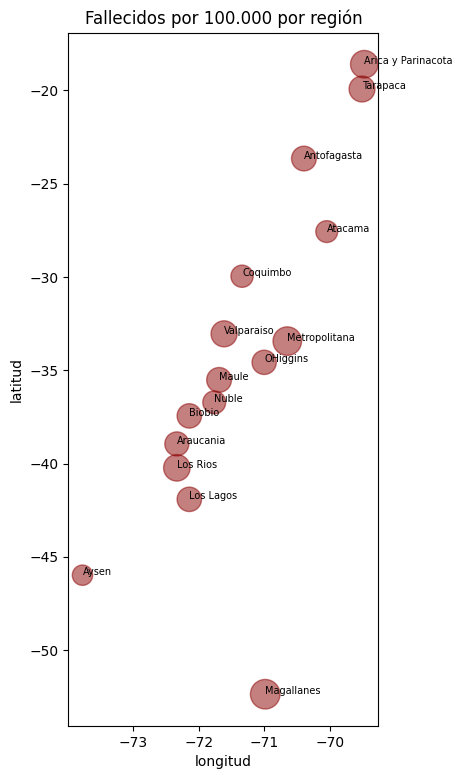

In [14]:
# Mapa de burbujas: fallecidos por 100.000 en cada región (posición de la tabla UID)
fig, ax = plt.subplots(figsize=(4, 9))
ax.scatter(p2['long'], p2['lat'], s=p2['fallecidos_x100k'], alpha=0.5, color='darkred')
for nombre, fila in p2.iterrows():
    ax.annotate(nombre.replace('Chile · ', ''), (fila['long'], fila['lat']), fontsize=7)
ax.set_title('Fallecidos por 100.000 por región')
ax.set_xlabel('longitud')
ax.set_ylabel('latitud')
plt.show()

### P4 · ¿Qué tan confiables son los datos de cada país?
Índice de calidad de `02_calidad` (100 = sin problemas detectados).

In [15]:
calidad = pd.read_parquet(os.path.join(LIMPIOS, 'calidad_por_pais.parquet'))
causas = {'dias_acum_baja': 'acumulado que baja', 'picos_rezago': 'picos por rezago',
          'dias_fallec_mayor': 'fallecidos > casos', 'dias_difiere_serie': 'difiere de la serie',
          'dias_sin_reporte': 'días sin reporte'}
calidad['causa_principal'] = calidad[list(causas.keys())].idxmax(axis=1).replace(causas)
peores = calidad[~calidad['pais'].isin(entidades_especiales)].sort_values('indice_calidad').head(10)
peores[['pais', 'indice_calidad', 'causa_principal']]

,pais,indice_calidad,causa_principal
91,"Korea, North",73.8,fallecidos > casos
125,Netherlands,81.5,difiere de la serie
186,United Kingdom,84.3,difiere de la serie
168,Sweden,85.0,difiere de la serie
65,Germany,85.4,difiere de la serie
35,Chile,90.2,difiere de la serie
133,Pakistan,91.5,difiere de la serie
37,Colombia,91.6,difiere de la serie
114,Mexico,92.2,difiere de la serie
182,US,92.7,difiere de la serie


### P6 · ¿Se podía anticipar la ola de ómicron en Chile?

Inicio de la ola de ómicron (incidencia > 100): 2022-01-09
     ola  inicio_ola  dias_de_anticipacion
2  Ola 3  2022-01-09                   2.0
               MAE  MAPE %
media_movil  579.0    26.4
tendencia    696.0    32.6


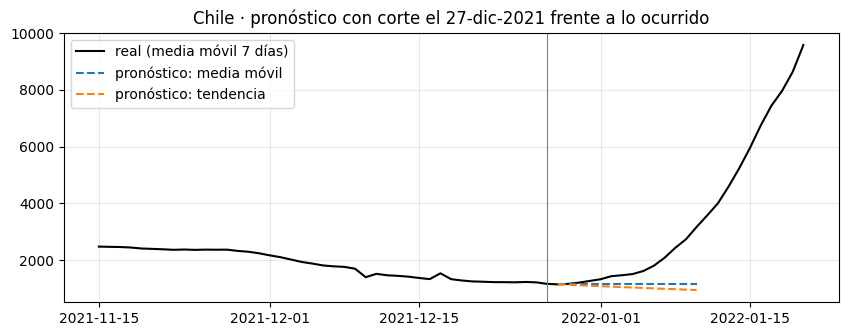

In [16]:
ola_omicron = olas_chile[olas_chile['inicio'] >= '2021-12-01'].iloc[0]
print('Inicio de la ola de ómicron (incidencia > 100):', ola_omicron['inicio'].date())
print(anticipacion[anticipacion['inicio_ola'] == ola_omicron['inicio'].date()])

p6, err6 = comparar('Chile', '2021-12-27')
print(err6)

fig, ax = plt.subplots(figsize=(10, 3.5))
hist = serie[(serie['territorio'] == 'Chile') & (serie['fecha'] >= '2021-11-15') & (serie['fecha'] <= '2022-01-20')]
ax.plot(hist['fecha'], hist['casos_mm7'], color='black', label='real (media móvil 7 días)')
ax.plot(p6['fecha'], p6['media_movil'], linestyle='--', label='pronóstico: media móvil')
ax.plot(p6['fecha'], p6['tendencia'], linestyle='--', label='pronóstico: tendencia')
ax.axvline(pd.Timestamp('2021-12-27'), color='gray', linewidth=0.8)
ax.set_title('Chile · pronóstico con corte el 27-dic-2021 frente a lo ocurrido')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 5 · Guardar la serie para el tablero

In [17]:
serie.to_parquet(os.path.join(LIMPIOS, 'serie_territorio.parquet'), index=False)
print('Guardado:', os.path.join(LIMPIOS, 'serie_territorio.parquet'),
      round(os.path.getsize(os.path.join(LIMPIOS, 'serie_territorio.parquet')) / 1e6, 1), 'MB')

Guardado: /content/drive/MyDrive/proyecto-gestion-datos-2026/data/clean/serie_territorio.parquet 4.7 MB
